# Mie spectra of Ag and Al spheres

This notebook calculates extinction, scattering, and absorption for spherical Ag and Al particles at radii 1, 5, 20, 50, and 100 nm. The assigned Drude model uses the stated material parameters and relative magnetic permeability $\mu_r=1$. A multipole convergence study, optical-data comparisons, and electric-field maps follow in separate sections.

**Run:** Keep this file, `data.d`, and the `data/` folder together. Install `numpy`, `scipy`, `matplotlib`, and `ipykernel`, select your Python kernel, then run cells from top to bottom. Figures are shown in their sections and saved to `results/`. All cells are intentionally unexecuted.

The optional Ag comparison uses Johnson–Christy optical constants in `data.d` (wavelength in µm, $n$, and $\kappa$). The Al comparison uses the bundled Hagemann table. Set `INCLUDE_EXPERIMENTAL = False` to skip comparisons or `MAKE_FIELD_MAPS = False` to skip the slower spatial maps.


## 1. Physical parameters

Each wavelength scan keeps the sphere radius fixed. The host is vacuum (`n=1`), and the relative permeability is 1. `Ep_eV` and `Gamma_eV` are the plasma and damping energies from the assignment. You can adjust the plotting density and field-map resolution in this cell.


In [2]:
from pathlib import Path
import csv
import json
import warnings

import numpy as np
from scipy.special import spherical_jn, spherical_yn
from scipy.interpolate import PchipInterpolator
import matplotlib.pyplot as plt




# A fixed radius is kept during every energy scan. Therefore x changes
# with energy. The two energy windows include the main Drude resonances.
RADII_NM = (1.0, 5.0, 20.0, 50.0, 100.0)
N_HOST = 1.0
N_HOMEWORK = 5
MATERIALS = {
    "Ag": {"eps_inf": 5.0, "Ep_eV": 9.5, "Gamma_eV": 0.1,
           "energy_range": (0.5, 6.0), "points": 2201,
           "data_file": "data.d", "data_label": "Johnson-Christy"},
    "Al": {"eps_inf": 1.25, "Ep_eV": 15.8, "Gamma_eV": 0.2,
           "energy_range": (0.5, 15.0), "points": 2901,
           "data_file": "Al_Hagemann_1974.csv", "data_label": "Hagemann compilation"},
}
INCLUDE_EXPERIMENTAL = True
MAKE_FIELD_MAPS = True
FIELD_RADIUS_NM = 50.0
FIELD_PIXELS = 240                 # increase for smoother maps
FIELD_EXTENT_RADII = 3.0           # plot x,z from -3a to +3a
CONVERGENCE_TOL = 0.01             # 1% of each reference spectrum's peak
REFERENCE_TOL = 1e-7               # reference vs four more multipoles
MIN_REFERENCE_ORDER = 12
MAX_REFERENCE_ORDER = 60
PNG_DPI = 180
HC_EV_NM = 1239.8419843320026       # h*c in eV nm
HERE = Path.cwd().resolve()
if not (HERE / "data").is_dir() and (HERE / "HW5_Mie_single" / "data").is_dir():
    HERE = HERE / "HW5_Mie_single"
if not (HERE / "data").is_dir():
    raise FileNotFoundError("The data/ folder is missing. Extract the complete package.")
KINDS = ("ext", "sca", "abs")
COLORS = {"ext": "#202c45", "sca": "#2478b5", "abs": "#d75c3a"}




## 2. Optical response

The Drude dielectric function is $\varepsilon(E)=\varepsilon_\infty-E_p^2/[E(E+i\Gamma)]$, where $E=\hbar\omega$ is photon energy in eV. For the optional tabulated comparison, $\varepsilon=(n+i\kappa)^2$ is interpolated only within the optical-data range.


In [3]:
def drude_epsilon(energy_eV, material):
    p = MATERIALS[material]
    energy = np.asarray(energy_eV, dtype=float)
    return p["eps_inf"] - p["Ep_eV"]**2 / (energy * (energy + 1j*p["Gamma_eV"]))


def load_optical_data(material):
    filename = MATERIALS[material]["data_file"]
    path = next((candidate for candidate in (HERE / filename, HERE / "data" / filename)
                 if candidate.is_file()), HERE / filename)
    if not path.is_file():
        raise FileNotFoundError(f"Missing {filename}. Place it beside this script or in data/.")
    if path.suffix == ".d":
        data = np.loadtxt(path)  # columns: wavelength_um, n, kappa
    else:
        data = np.loadtxt(path, delimiter=",", skiprows=1)
    data = data[np.argsort(data[:, 0])]
    if np.any(np.diff(data[:, 0]) <= 0):
        raise ValueError(f"Wavelengths must be unique in {path.name}.")
    return data


def tabulated_epsilon(energy_eV, data):
    lam_um = HC_EV_NM / np.asarray(energy_eV) / 1000
    if np.any(lam_um < data[0, 0]) or np.any(lam_um > data[-1, 0]):
        raise ValueError("Energy outside the optical-data range; extrapolation is disabled.")
    nr = PchipInterpolator(data[:, 0], data[:, 1], extrapolate=False)(lam_um)
    ki = PchipInterpolator(data[:, 0], data[:, 2], extrapolate=False)(lam_um)
    return (nr + 1j*ki)**2




## 3. Mie coefficients

The electric coefficients `a_n` and magnetic coefficients `b_n` describe dipoles (`n=1`), quadrupoles (`n=2`), and higher multipoles. They follow by matching the electromagnetic fields at the sphere surface. The internal coefficients `c_n,d_n` are needed for the field maps.


In [4]:

# psi_n(z)=z*j_n(z), xi_n(z)=z*h_n^(1)(z). Tangential E and H continuity
# at r=a determines the coefficients. Orders start at n=1 (dipole).
# Internal coefficients are included for the later electric-field maps.
def mie_coefficients(x, m, nmax):
    x, m = np.broadcast_arrays(np.asarray(x, dtype=float), np.asarray(m, dtype=complex))
    if nmax < 1 or np.any(x <= 0):
        raise ValueError("Require nmax>=1 and positive size parameters.")
    n = np.arange(1, nmax+1).reshape((nmax,) + (1,)*x.ndim)
    xx, zz = x[None, ...], (m*x)[None, ...]
    jx = spherical_jn(n, xx)
    jz = spherical_jn(n, zz)
    hx = jx + 1j*spherical_yn(n, xx)
    psi_x, psi_z, xi_x = xx*jx, zz*jz, xx*hx
    dp_x = jx + xx*spherical_jn(n, xx, derivative=True)
    dp_z = jz + zz*spherical_jn(n, zz, derivative=True)
    dx_x = hx + xx*(spherical_jn(n, xx, derivative=True)
                   + 1j*spherical_yn(n, xx, derivative=True))
    den_a = m*psi_z*dx_x - xi_x*dp_z
    den_b = psi_z*dx_x - m*xi_x*dp_z
    a = (m*psi_z*dp_x - psi_x*dp_z) / den_a
    b = (psi_z*dp_x - m*psi_x*dp_z) / den_b
    # Wronskian psi*xi' - xi*psi' = i; BOTH internal numerators contain m.
    c = 1j*m / den_b
    d = 1j*m / den_a
    if not all(np.all(np.isfinite(v)) for v in (a, b, c, d)):
        raise FloatingPointError("Non-finite Mie coefficients; inspect the chosen parameters.")
    return a, b, c, d




## 4. Extinction, scattering, and absorption

`Qext` is the light removed from the incident beam, `Qsca` is reradiated light, and `Qabs = Qext − Qsca` is dissipated light. Each efficiency is dimensionless; the output tables also give cross sections `C = πa²Q` in nm². The homework plots sum multipoles through `N=5`.


In [5]:

# Extinction is energy removed from the incident beam. Part is reradiated
# (scattering), and the remainder is dissipated (absorption).
# Efficiencies are dimensionless; cross sections below are in nm^2.
def spectrum(energy, radius, epsilon, nmax, n_host=N_HOST):
    energy = np.asarray(energy, dtype=float)
    wavelength = HC_EV_NM / energy
    x = 2*np.pi*n_host*radius / wavelength
    m = np.sqrt(np.asarray(epsilon, dtype=complex)) / n_host
    a, b, _, _ = mie_coefficients(x, m, nmax)
    n = np.arange(1, nmax+1)[:, None]
    weight = 2*(2*n+1) / x[None, :]**2
    ext_e, ext_m = weight*a.real, weight*b.real
    sca_e, sca_m = weight*np.abs(a)**2, weight*np.abs(b)**2
    qext = np.sum(ext_e+ext_m, axis=0)
    qsca = np.sum(sca_e+sca_m, axis=0)
    qabs = qext-qsca
    # Do not clip negative absorption silently: it can reveal a sign error.
    if np.min(qabs) < -1e-9*max(1.0, float(np.max(qext))):
        raise ValueError("Significantly negative absorption for a passive material.")
    return {"energy": energy, "wavelength": wavelength, "x": x,
            "ext": qext, "sca": qsca, "abs": qabs,
            "ext_e": ext_e, "ext_m": ext_m,
            "sca_e": sca_e, "sca_m": sca_m, "nmax": nmax}




## 5. Does five multipoles suffice?

The code compares truncations `N=1,…,5` with a larger sum. It checks that the larger reference hardly changes after adding another four orders. The 1% threshold is a chosen diagnostic, measured relative to the peak of each reference spectrum. The final results will identify any radius and energy range where `N=5` needs care.


In [6]:

# Error = max_E |Q_N-Q_ref| / max_E |Q_ref|, separately for ext/sca/abs.
# This avoids meaningless pointwise relative errors in almost-zero tails.
# A reference is checked against four extra orders before being accepted.
# These extra orders are a diagnostic; homework spectra are still N=5.
def spectral_errors(trial, reference):
    return {q: float(np.max(np.abs(trial[q]-reference[q])) /
                     max(float(np.max(np.abs(reference[q]))), 1e-30)) for q in KINDS}


def converged_reference(energy, radius, epsilon):
    xmax = 2*np.pi*N_HOST*radius*np.max(energy)/HC_EV_NM
    nref = max(MIN_REFERENCE_ORDER, N_HOMEWORK+4,
               int(np.ceil(xmax + 4*np.cbrt(xmax) + 2))+4)
    while nref+4 <= MAX_REFERENCE_ORDER:
        low = spectrum(energy, radius, epsilon, nref)
        high = spectrum(energy, radius, epsilon, nref+4)
        err = max(spectral_errors(low, high).values())
        if err < REFERENCE_TOL:
            return low, err
        nref += 4
    raise RuntimeError("Reference did not stabilize; inspect parameters before increasing the limit.")




## 6. Electric field around the sphere

For a wave traveling along `+z` and polarized along `x`, the exterior total field combines incident and scattered contributions. The interior field uses regular spherical functions. The maps show total electric-field enhancement, the scattered field outside, and a snapshot of the real electric field.


In [7]:

# Incident E=E0*exp(i*k*z)*e_x. In the x-z plane E_y=0 by symmetry.
# Outside: E_s=sum E_n*(i*a_n*N_e - b_n*M_o).
# Inside:  E_i=sum E_n*(c_n*M_o - i*d_n*N_e).
# Here pi_1=1, tau_1=cos(theta); the convention is used consistently.
# E0 multiplies every term. Hankel functions are evaluated ONLY outside.
def electric_field_xz(X, Z, energy, radius, epsilon, nmax, E0=1.0, n_host=N_HOST):
    X, Z = np.broadcast_arrays(np.asarray(X, float), np.asarray(Z, float))
    shape = X.shape
    xf, zf = X.ravel(), Z.ravel()
    rr = np.hypot(xf, zf)
    outside = rr >= radius
    k = 2*np.pi*n_host*energy/HC_EV_NM
    m = np.sqrt(complex(epsilon))/n_host
    a, b, c, d = mie_coefficients(k*radius, m, nmax)
    inc = E0*np.exp(1j*k*zf)
    ex, ez = np.zeros(rr.size, complex), np.zeros(rr.size, complex)
    sx = np.full(rr.size, complex(np.nan, np.nan))
    sz = sx.copy()
    for mask, external in ((outside, True), (~outside, False)):
        if not np.any(mask):
            continue
        r = rr[mask]
        cost = np.divide(zf[mask], r, out=np.ones_like(r), where=r>0)
        cost = np.clip(cost, -1, 1)
        sint = np.sqrt(np.maximum(0, 1-cost**2))
        cosphi = np.where(xf[mask] >= 0, 1.0, -1.0)
        rho = (k if external else m*k)*np.where(r>0, r, 1e-12*radius)
        er, et = np.zeros(r.size, complex), np.zeros(r.size, complex)
        pi_prev, pi_now = np.zeros(r.size), np.ones(r.size)
        for n in range(1, nmax+1):
            tau = n*cost*pi_now - (n+1)*pi_prev
            radial = spherical_jn(n, rho)
            radial_p = spherical_jn(n, rho, derivative=True)
            if external:
                radial = radial + 1j*spherical_yn(n, rho)
                radial_p = radial_p + 1j*spherical_yn(n, rho, derivative=True)
            n_rad = n*(n+1)*sint*pi_now*radial/rho
            n_tan = tau*(radial+rho*radial_p)/rho
            m_tan = pi_now*radial
            en = E0*(1j)**n*(2*n+1)/(n*(n+1))
            if external:
                er += en*1j*a[n-1]*cosphi*n_rad
                et += en*cosphi*(1j*a[n-1]*n_tan-b[n-1]*m_tan)
            else:
                er += en*(-1j)*d[n-1]*cosphi*n_rad
                et += en*cosphi*(c[n-1]*m_tan-1j*d[n-1]*n_tan)
            pi_prev, pi_now = pi_now, ((2*n+1)*cost*pi_now-(n+1)*pi_prev)/n
        ex_part = cosphi*(er*sint+et*cost)
        ez_part = er*cost-et*sint
        if external:
            sx[mask], sz[mask] = ex_part, ez_part
            ex[mask], ez[mask] = inc[mask]+ex_part, ez_part
        else:
            ex[mask], ez[mask] = ex_part, ez_part
    # Exact regular limit at r=0: only the electric dipole contributes.
    ex[rr == 0], ez[rr == 0] = E0*d[0], 0.0
    return tuple(v.reshape(shape) for v in (ex, ez, sx, sz))




## 7. Numerical checks

Check the expected limits and energy balance before interpreting the plots.


In [8]:

# Energy balance alone is not a test because Qabs is defined by subtraction.
# Independent limits below check transparency, zero loss, Rayleigh scattering,
# correct incident-field recovery, amplitude scaling, and boundary conditions.
def physics_checks():
    energy = np.linspace(1, 4, 51)
    same = spectrum(energy, 30, np.ones_like(energy), 8, n_host=1.0)
    assert max(np.max(np.abs(same[q])) for q in KINDS) < 1e-10
    lossless = spectrum(energy, 50, np.full_like(energy, 2.25), 12, n_host=1.0)
    assert np.max(np.abs(lossless["abs"])) < 1e-10
    small_x = 1e-3
    a, b, _, _ = mie_coefficients(small_x, 1.5+0j, 4)
    actual = 2/small_x**2*np.sum((2*np.arange(1, 5)+1)*(abs(a)**2+abs(b)**2))
    rayleigh = (8/3)*small_x**4*abs((2.25-1)/(2.25+2))**2
    assert abs(actual/rayleigh-1) < 1e-4
    xx = np.array([0., 8., -12., 70.])
    zz = np.array([0., 14., 18., 80.])
    ex, ez, _, _ = electric_field_xz(xx, zz, 2.0, 50, 1.0, 14, E0=1.7, n_host=1.0)
    exact = 1.7*np.exp(1j*2*np.pi*2.0/HC_EV_NM*zz)
    assert np.max(np.abs(ex-exact)) < 1e-9 and np.max(np.abs(ez)) < 1e-9
    f1 = electric_field_xz(xx, zz, 2., 50., 2.25+0.2j, 14, E0=1., n_host=1.)
    f2 = electric_field_xz(xx, zz, 2., 50., 2.25+0.2j, 14, E0=2., n_host=1.)
    assert max(np.max(np.abs(f2[i]-2*f1[i])) for i in (0, 1)) < 1e-10
    theta = np.linspace(0.15, np.pi-0.15, 17)
    eps = 2.25+0.2j
    rin, rout = 50*(1-1e-7), 50*(1+1e-7)
    fi = electric_field_xz(rin*np.sin(theta), rin*np.cos(theta), 3., 50., eps, 16, n_host=1.)
    fo = electric_field_xz(rout*np.sin(theta), rout*np.cos(theta), 3., 50., eps, 16, n_host=1.)
    eti = fi[0]*np.cos(theta)-fi[1]*np.sin(theta)
    eto = fo[0]*np.cos(theta)-fo[1]*np.sin(theta)
    dri = eps*(fi[0]*np.sin(theta)+fi[1]*np.cos(theta))
    dro = fo[0]*np.sin(theta)+fo[1]*np.cos(theta)
    assert np.max(np.abs(eti-eto)) < 1e-4
    assert np.max(np.abs(dri-dro)) < 1e-4
    return "PASS: index matching, lossless sphere, Rayleigh limit, field recovery, E0 scaling, E/D boundary continuity."




In [9]:
OUT = HERE / "results"
OUT.mkdir(parents=True, exist_ok=True)
if N_HOST <= 0 or FIELD_PIXELS < 20:
    raise ValueError("Require a positive host index and FIELD_PIXELS >= 20.")
plt.rcParams.update({"font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False})
check_message = physics_checks()
print(check_message)


PASS: index matching, lossless sphere, Rayleigh limit, field recovery, E0 scaling, E/D boundary continuity.


## 8. Plotting and per-material calculations

Define figure styles and a helper that evaluates each radius and saves spectra.


In [10]:
def save_figure(fig, out, stem, show=False):
    fig.savefig(out/(stem+".png"), dpi=PNG_DPI, bbox_inches="tight")
    fig.savefig(out/(stem+".pdf"), bbox_inches="tight")
    if not show:
        plt.close(fig)


def write_rows(path, rows):
    with path.open("w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)


def save_spectrum(path, result, radius):
    area = np.pi*radius**2
    columns = [result["energy"], result["wavelength"], result["x"]]
    columns += [result[q] for q in KINDS]
    columns += [area*result[q] for q in KINDS]
    np.savetxt(path, np.column_stack(columns), delimiter=",",
               header="E_eV,wavelength_nm,x,Qext,Qsca,Qabs,Cext_nm2,Csca_nm2,Cabs_nm2",
               comments="")


def plot_spectra(material, cases, out, show):
    fig, axes = plt.subplots(len(RADII_NM), 1, figsize=(9, 2.5*len(RADII_NM)),
                             sharex=True, layout="constrained", squeeze=False)
    for ax, radius in zip(axes[:, 0], RADII_NM):
        s = cases[radius]["hw"]
        for q in KINDS:
            ax.plot(s["energy"], s[q], color=COLORS[q], label=f"{q.capitalize()}")
        err = max(cases[radius]["errors"][-1].values())
        note = "" if err <= CONVERGENCE_TOL else " | see convergence diagnostic"
        ax.set_title(f"Radius {radius:g} nm{note}", fontsize=10)
        ax.set_ylabel("Efficiency Q")
        ax.grid(alpha=.2)
        ax.set_ylim(bottom=0)
    axes[0, 0].legend(ncol=3)
    axes[-1, 0].set_xlabel("Photon energy E (eV)")
    fig.suptitle(f"{material}: Drude spectra (N={N_HOMEWORK})")
    save_figure(fig, out, f"01_{material}_Drude_spectra", show)


def plot_convergence(material, cases, out, show):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), layout="constrained")
    orders = np.arange(1, N_HOMEWORK+1)
    for radius in RADII_NM:
        case = cases[radius]
        errors = [100*max(err.values()) for err in case["errors"]]
        line, = axes[0].semilogy(orders, np.maximum(errors, 1e-12), "o-", label=f"{radius:g} nm")
        ref, hw = case["ref"], case["hw"]
        point_error = np.max([np.abs(hw[q]-ref[q])/max(np.max(np.abs(ref[q])), 1e-30)
                              for q in KINDS], axis=0)
        axes[1].plot(hw["energy"], 100*point_error, color=line.get_color(), label=f"{radius:g} nm")
    for ax in axes:
        ax.axhline(100*CONVERGENCE_TOL, ls=":", color="gray", label="1% tolerance")
        ax.grid(alpha=.2)
        ax.set_ylabel("Worst peak-normalized error (%)")
    axes[0].set_xticks(orders)
    axes[0].set_xlabel("Maximum multipole order N")
    axes[0].legend(fontsize=8)
    axes[1].set_xlabel("Photon energy E (eV)")
    axes[0].set_title("Maximum over energy and the three spectra")
    axes[1].set_title(f"Energy dependence of the N={N_HOMEWORK} error")
    fig.suptitle(f"{material}: multipole convergence")
    save_figure(fig, out, f"02_{material}_convergence", show)


def plot_multipoles(material, cases, out, show):
    # Extinction weights reveal why additional peaks emerge as size grows.
    selected = [RADII_NM[0], RADII_NM[-1]]
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), layout="constrained")
    for ax, radius in zip(axes, selected):
        s = cases[radius]["ref"]
        for i in range(min(N_HOMEWORK, s["nmax"])):
            ax.plot(s["energy"], s["ext_e"][i], label=f"Electric n={i+1}")
        ax.plot(s["energy"], s["ext_m"].sum(axis=0), "--", color="gray", label="All magnetic")
        if s["nmax"] > N_HOMEWORK:
            ax.plot(s["energy"], s["ext_e"][N_HOMEWORK:].sum(axis=0), ":", color="purple",
                    label=f"Electric n>{N_HOMEWORK}")
        ax.plot(s["energy"], s["ext"], color="black", lw=1, alpha=.6, label="Total")
        ax.set(title=f"Radius {radius:g} nm", xlabel="Photon energy (eV)", ylabel="Partial extinction Q")
        ax.grid(alpha=.2)
    axes[1].legend(fontsize=8)
    fig.suptitle(f"{material}: extinction by multipole")
    save_figure(fig, out, f"03_{material}_multipoles", show)


def plot_experimental(material, energy, epsilon, data, out, show, summary):
    fig, axes = plt.subplots(len(RADII_NM), 1, figsize=(9, 2.5*len(RADII_NM)),
                             sharex=True, layout="constrained", squeeze=False)
    for ax, radius in zip(axes[:, 0], RADII_NM):
        exp, err_exp = converged_reference(energy, radius, epsilon)
        dru, err_dru = converged_reference(energy, radius, drude_epsilon(energy, material))
        for q in KINDS:
            ax.plot(energy, dru[q], "--", color=COLORS[q], alpha=.7, label=f"Drude {q}")
            ax.plot(energy, exp[q], color=COLORS[q], label=f"Tabulated {q}")
        ax.set(title=f"Radius {radius:g} nm", ylabel="Efficiency Q")
        ax.set_ylim(bottom=0)
        ax.grid(alpha=.2)
        save_spectrum(out/f"extra_{material}_{radius:g}nm_tabulated.csv", exp, radius)
        save_spectrum(out/f"extra_{material}_{radius:g}nm_Drude_same_grid.csv", dru, radius)
        i, j = int(np.argmax(dru["ext"])), int(np.argmax(exp["ext"]))
        summary.append(f"{material}, {radius:g} nm: dominant extinction peak on shared window: "
                       f"Drude {energy[i]:.4f} eV; tabulated {energy[j]:.4f} eV. "
                       f"Reference N={dru['nmax']}/{exp['nmax']}; stability errors "
                       f"{err_dru:.2e}/{err_exp:.2e}.")
        if i in (0, len(energy)-1) or j in (0, len(energy)-1):
            summary.append("  At least one maximum is at a window boundary; do not call it a resolved resonance.")
    axes[0, 0].legend(ncol=3, fontsize=8)
    axes[-1, 0].set_xlabel("Photon energy E (eV)")
    fig.suptitle(f"{material}: Drude vs optical data")
    save_figure(fig, out, f"04_{material}_tabulated_comparison", show)
    # Raw optical-data points help distinguish the table from interpolation.
    fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
    raw_e = HC_EV_NM/(1000*data[:, 0])
    mask = (raw_e>=energy.min()) & (raw_e<=energy.max())
    raw_eps = (data[:, 1]+1j*data[:, 2])**2
    for ax, part, label in zip(axes, (np.real, np.imag), ("Real", "Imaginary")):
        ax.plot(energy, part(drude_epsilon(energy, material)), "--", label="Drude")
        ax.plot(energy, part(epsilon), label="Interpolated table")
        ax.plot(raw_e[mask], part(raw_eps[mask]), ".", ms=3, label="Tabulated points")
        ax.set(xlabel="Photon energy (eV)", ylabel=f"{label} permittivity")
        ax.grid(alpha=.2)
        ax.legend(fontsize=8)
    fig.suptitle(f"{material}: dielectric function")
    save_figure(fig, out, f"05_{material}_dielectric_comparison", show)


def plot_fields(material, out, show, summary):
    radius = FIELD_RADIUS_NM
    p = MATERIALS[material]
    energy = np.linspace(*p["energy_range"], p["points"])
    ref, _ = converged_reference(energy, radius, drude_epsilon(energy, material))
    peak_i = int(np.argmax(ref["sca"]))
    peak_e = energy[peak_i]
    if peak_i in (0, len(energy)-1):
        warnings.warn(f"{material}: scattering maximum lies at a field-scan boundary.")
    # Choose a low-energy point on the red side for a useful comparison.
    off_e = max(energy[0], 0.6*peak_e)
    axis = np.linspace(-FIELD_EXTENT_RADII*radius, FIELD_EXTENT_RADII*radius, FIELD_PIXELS)
    X, Z = np.meshgrid(axis, axis)
    fig, axes = plt.subplots(2, 3, figsize=(13, 8), layout="constrained")
    for row, (label, en) in enumerate((("Off resonance", off_e), ("Scattering maximum", peak_e))):
        eps = drude_epsilon(en, material)
        nuse = ref["nmax"]
        ex, ez, sx, sz = electric_field_xz(X, Z, en, radius, eps, nuse)
        # Check field convergence itself; far-field convergence does not imply it.
        ex2, ez2, sx2, sz2 = electric_field_xz(X, Z, en, radius, eps, nuse+4)
        field_error = max(np.max(abs(ex2-ex)), np.max(abs(ez2-ez))) / max(1., np.max(np.hypot(abs(ex2), abs(ez2))))
        if field_error > 1e-4:
            raise RuntimeError(f"Field convergence insufficient for {material}: {field_error:.2e}")
        total = abs(ex)**2+abs(ez)**2
        scattered = abs(sx)**2+abs(sz)**2
        realx = np.real(ex)
        # Log color scales reveal weak and strong fields simultaneously.
        # E0=1, so these are |E/E0|^2 and |Esca/E0|^2.
        titles = ("Total field: log10(|E/E0|^2)", "Scattered field: log10(|Esca/E0|^2)", "Snapshot: Re(Ex/E0), t=0")
        images = (np.log10(np.maximum(total, 1e-8)),
                  np.log10(np.maximum(scattered, 1e-8)), realx)
        for col, (title, im) in enumerate(zip(titles, images)):
            ax = axes[row, col]
            if col == 2:
                limit = max(1., float(np.max(abs(realx))))
                artist = ax.pcolormesh(X/radius, Z/radius, im, shading="auto", cmap="RdBu_r", vmin=-limit, vmax=limit)
                step = max(1, FIELD_PIXELS//18)
                # Fixed length arrows show direction only; color shows Re(Ex).
                rx, rz = ex.real[::step, ::step], ez.real[::step, ::step]
                norm = np.maximum(np.hypot(rx, rz), 1e-15)
                ax.quiver((X/radius)[::step, ::step], (Z/radius)[::step, ::step], rx/norm, rz/norm,
                          color="black", alpha=.5, scale=30, width=.002)
            else:
                artist = ax.pcolormesh(X/radius, Z/radius, im, shading="auto", cmap="magma",
                                       vmin=(-2 if col == 0 else -6), vmax=3)
                if col == 1:
                    ax.add_patch(plt.Circle((0, 0), 1, color="#d9dde3"))
            ax.add_patch(plt.Circle((0, 0), 1, fill=False, edgecolor="cyan", lw=1))
            ax.set(aspect="equal", xlabel="x/a", ylabel="z/a", title=title)
            fig.colorbar(artist, ax=ax, shrink=.8, extend="both" if col<2 else "neither")
        axes[row, 0].set_ylabel(f"{label}\nE={en:.3f} eV; lambda={HC_EV_NM/en:.1f} nm\nz/a")
        np.savez_compressed(out/f"field_{material}_{radius:g}nm_{label.replace(' ', '_')}.npz",
                            x_nm=axis, z_nm=axis, Ex=ex, Ez=ez, Esca_x=sx, Esca_z=sz,
                            energy_eV=en, epsilon=eps, radius_nm=radius, nmax=nuse,
                            field_convergence_error=field_error)
        summary.append(f"Field {material}, a={radius:g} nm, {label}: E={en:.5f} eV, "
                       f"N={nuse}, field change vs N+4={field_error:.2e}.")
    fig.suptitle(f"{material}: electric field (a={radius:g} nm)")
    save_figure(fig, out, f"06_{material}_electric_fields", show)




In [11]:
def calculate_cases(material):
    """Compute the assigned radii and save each spectrum for one metal."""
    p = MATERIALS[material]
    energy = np.linspace(*p["energy_range"], p["points"])
    epsilon = drude_epsilon(energy, material)
    cases, convergence_rows, peak_rows = {}, [], []
    quasi = p["Ep_eV"] / np.sqrt(p["eps_inf"] + 2*N_HOST**2)
    notes = [f"{material}: Drude eps_inf={p['eps_inf']}, Ep={p['Ep_eV']} eV, Gamma={p['Gamma_eV']} eV.",
             f"Energy window {energy[0]}-{energy[-1]} eV; electrostatic dipole guide: {quasi:.4f} eV."]
    for radius in RADII_NM:
        ref, ref_error = converged_reference(energy, radius, epsilon)
        trials = [spectrum(energy, radius, epsilon, n)
                  for n in range(1, N_HOMEWORK+1)]
        errors = [spectral_errors(s, ref) for s in trials]
        hw = trials[-1]
        cases[radius] = {"ref": ref, "hw": hw, "errors": errors}
        for n, errs in enumerate(errors, 1):
            convergence_rows.append({"material": material, "radius_nm": radius, "N": n,
                **{f"error_{q}_percent": 100*errs[q] for q in KINDS},
                "reference_N": ref["nmax"], "reference_stability": ref_error})
        worst = max(errors[-1].values())
        passing = [i+1 for i, err in enumerate(errors)
                   if max(err.values()) <= CONVERGENCE_TOL]
        notes.append(f"a={radius:g} nm: N={N_HOMEWORK} error={100*worst:.4g}%; "
                     f"first N<=5 meeting 1%: {min(passing) if passing else 'none'}; "
                     f"reference N={ref['nmax']}, stability={ref_error:.2e}.")
        for label, result in ((f"N{N_HOMEWORK}", hw), ("reference", ref)):
            save_spectrum(OUT/f"{material}_{radius:g}nm_{label}.csv", result, radius)
            for q in KINDS:
                i = int(np.argmax(result[q]))
                peak_rows.append({"material": material, "radius_nm": radius,
                    "calculation": label, "quantity": q,
                    "peak_energy_eV": energy[i], "peak_wavelength_nm": HC_EV_NM/energy[i],
                    "peak_Q": result[q][i],
                    "peak_C_nm2": np.pi*radius**2*result[q][i],
                    "at_window_boundary": i in (0, len(energy)-1)})
    return cases, convergence_rows, peak_rows, notes


## 9. Silver: Drude spectra

The curves show extinction, scattering and absorption efficiency for each assigned radius.


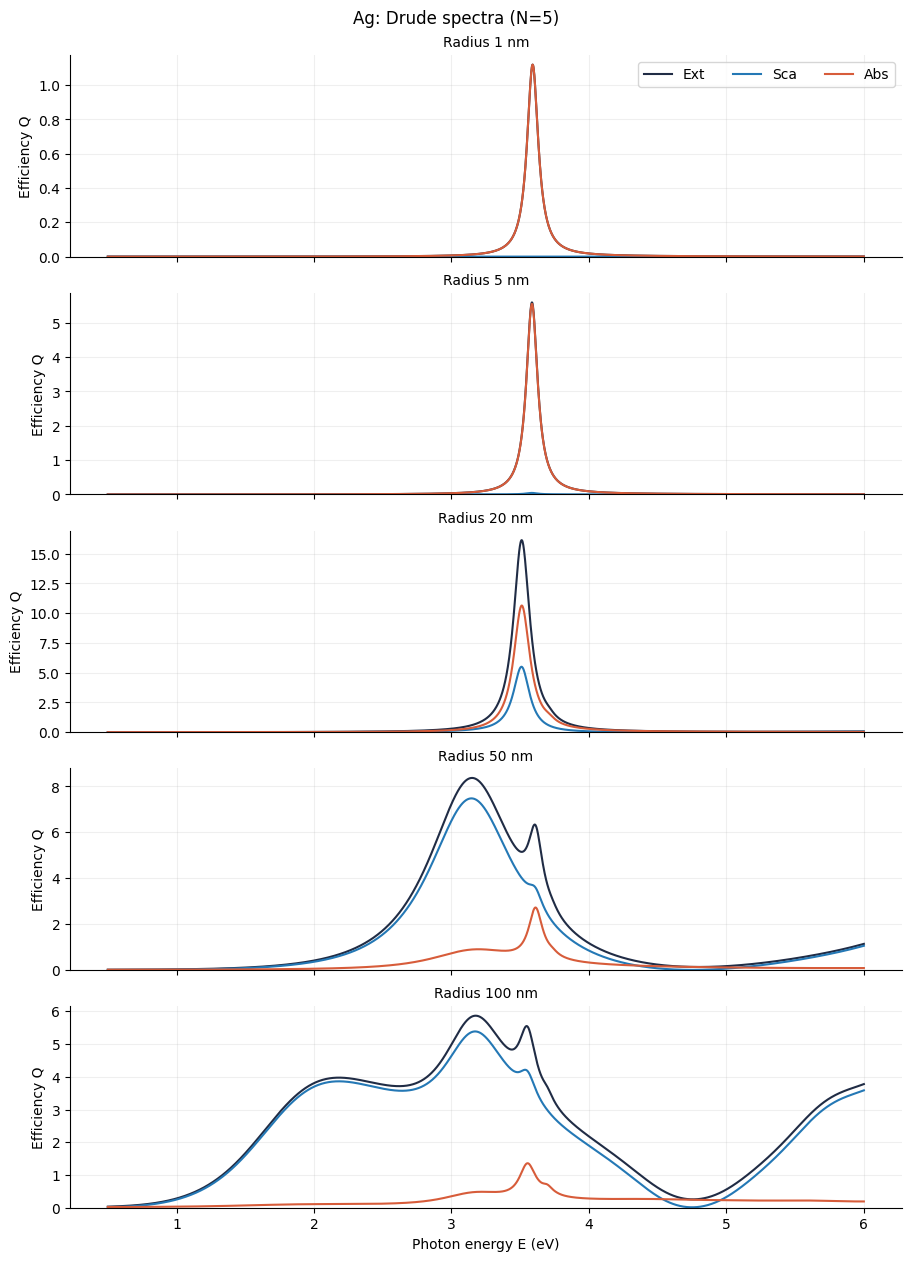

Ag: Drude eps_inf=5.0, Ep=9.5 eV, Gamma=0.1 eV.
Energy window 0.5-6.0 eV; electrostatic dipole guide: 3.5907 eV.
a=1 nm: N=5 error=0%; first N<=5 meeting 1%: 1; reference N=12, stability=0.00e+00.
a=5 nm: N=5 error=0%; first N<=5 meeting 1%: 1; reference N=12, stability=0.00e+00.
a=20 nm: N=5 error=8.075e-11%; first N<=5 meeting 1%: 2; reference N=12, stability=0.00e+00.
a=50 nm: N=5 error=7.138e-06%; first N<=5 meeting 1%: 3; reference N=13, stability=0.00e+00.
a=100 nm: N=5 error=0.02408%; first N<=5 meeting 1%: 4; reference N=15, stability=0.00e+00.


In [12]:
ag_cases, ag_convergence, ag_peaks, ag_notes = calculate_cases("Ag")
plot_spectra("Ag", ag_cases, OUT, True)
plt.show()
print("\n".join(ag_notes))


### Silver: convergence of the multipole sum

Compare orders 1–5 with a stable higher-order reference. The table is saved later.


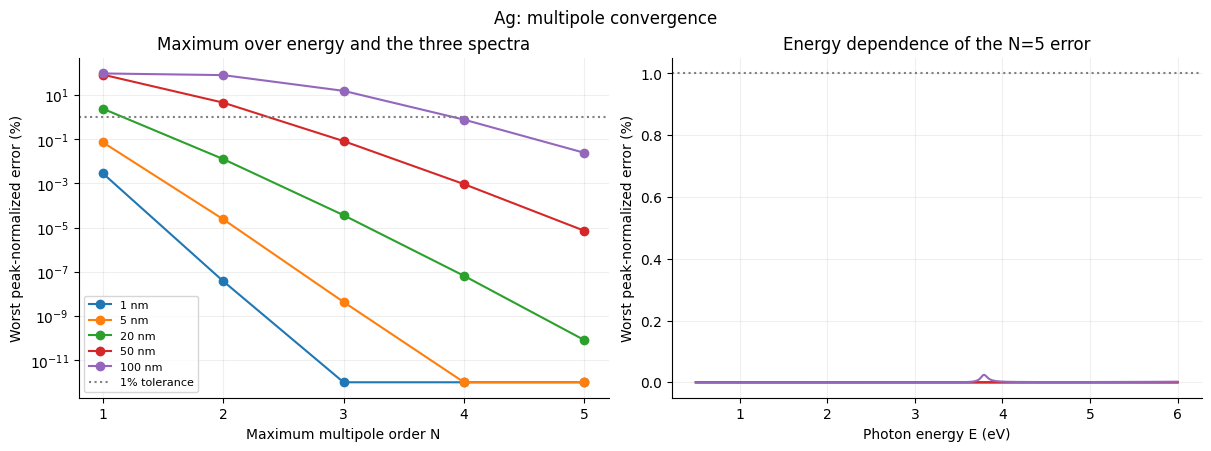

In [13]:
plot_convergence("Ag", ag_cases, OUT, True)
plt.show()


### Silver: dipole and higher multipoles

This plot separates individual multipole contributions to the spectrum.


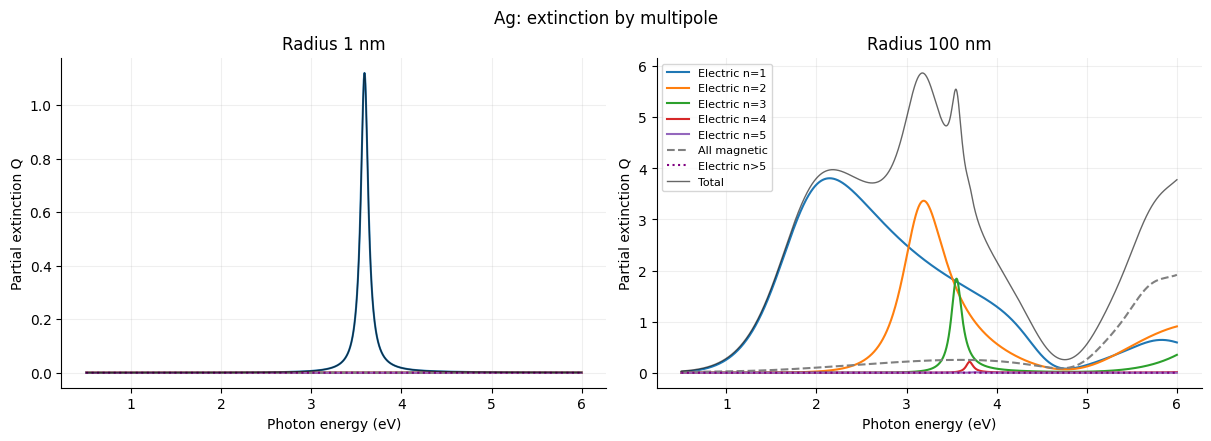

In [14]:
plot_multipoles("Ag", ag_cases, OUT, True)
plt.show()


## 10. Aluminum: Drude spectra

Repeat the same calculation with the aluminum Drude parameters.


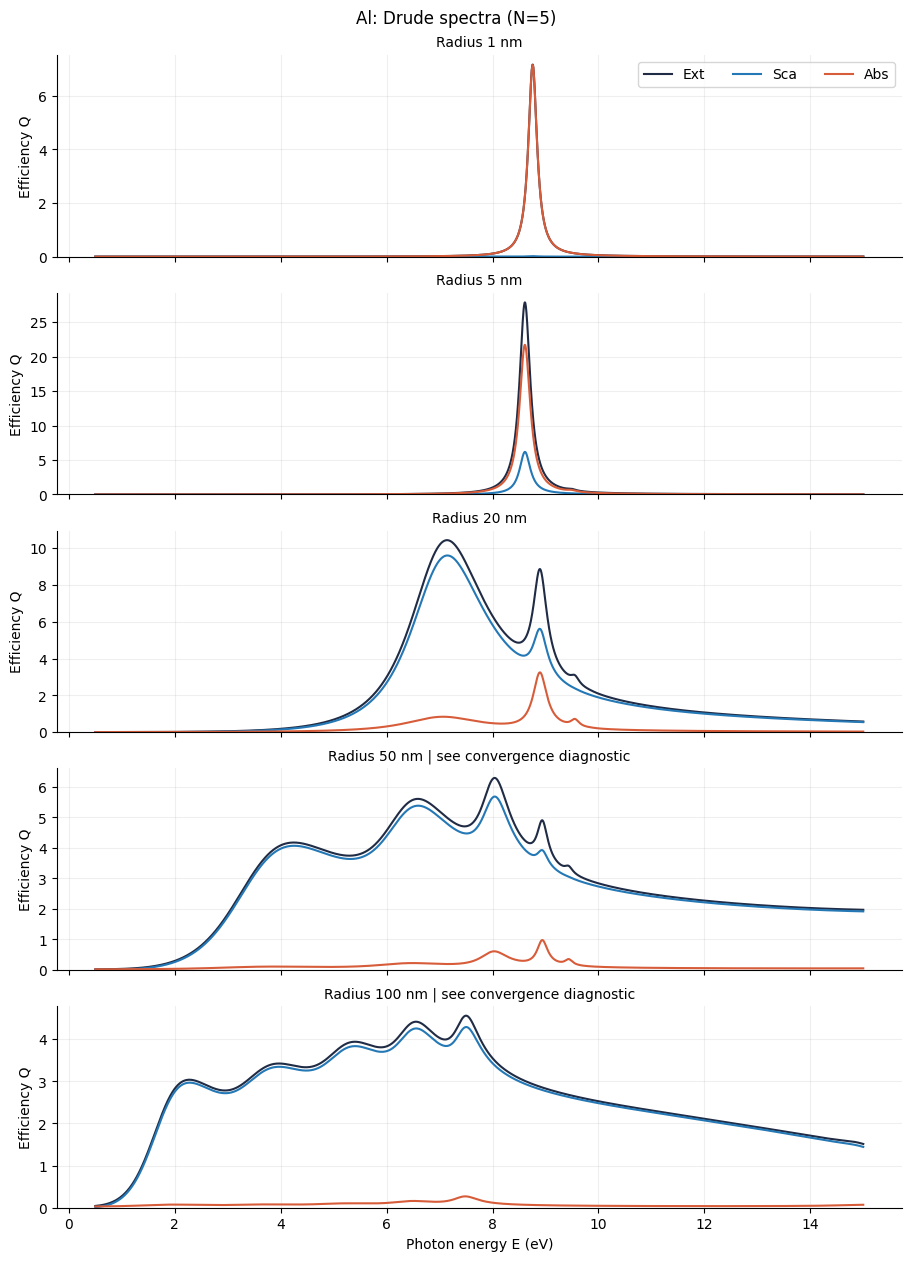

Al: Drude eps_inf=1.25, Ep=15.8 eV, Gamma=0.2 eV.
Energy window 0.5-15.0 eV; electrostatic dipole guide: 8.7643 eV.
a=1 nm: N=5 error=0%; first N<=5 meeting 1%: 1; reference N=12, stability=0.00e+00.
a=5 nm: N=5 error=1.489e-12%; first N<=5 meeting 1%: 1; reference N=12, stability=0.00e+00.
a=20 nm: N=5 error=3.692e-05%; first N<=5 meeting 1%: 3; reference N=13, stability=0.00e+00.
a=50 nm: N=5 error=1.429%; first N<=5 meeting 1%: none; reference N=17, stability=0.00e+00.
a=100 nm: N=5 error=79.71%; first N<=5 meeting 1%: none; reference N=22, stability=0.00e+00.


In [15]:
al_cases, al_convergence, al_peaks, al_notes = calculate_cases("Al")
plot_spectra("Al", al_cases, OUT, True)
plt.show()
print("\n".join(al_notes))


### Aluminum: convergence of the multipole sum

At large radii, check whether five orders meet the chosen 1% accuracy target.


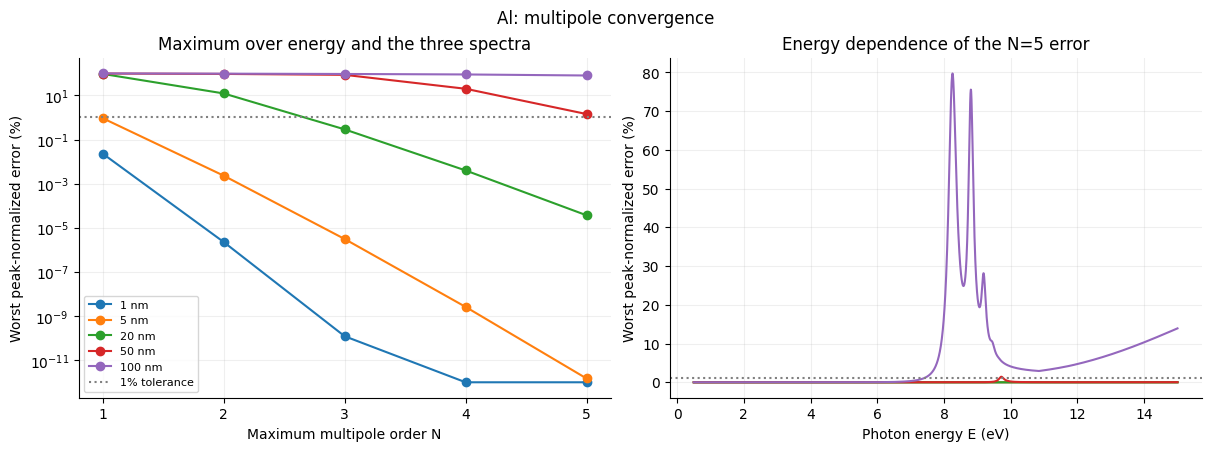

In [16]:
plot_convergence("Al", al_cases, OUT, True)
plt.show()


### Aluminum: dipole and higher multipoles

Higher-order modes become more visible as the radius increases.


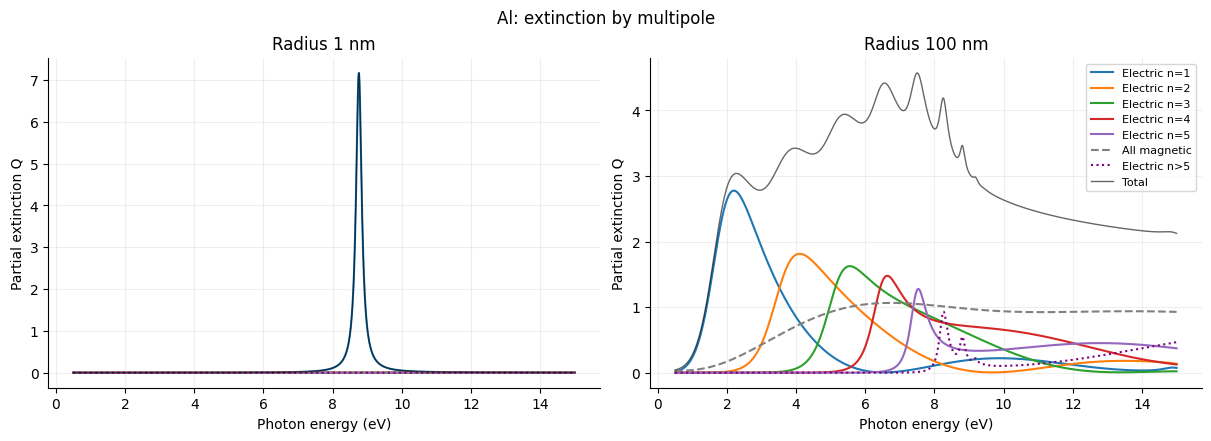

In [17]:
plot_multipoles("Al", al_cases, OUT, True)
plt.show()


## 11. Optical data: silver

Compare Drude with the Johnson–Christy $n,\kappa$ values in `data.d`, within their tabulated wavelength range. Both curves are Mie predictions for spheres.


In [18]:
def compare_with_data(material, notes):
    """Use only wavelengths covered by the measured optical constants."""
    p = MATERIALS[material]
    energy = np.linspace(*p["energy_range"], p["points"])
    data = load_optical_data(material)
    wavelength_um = HC_EV_NM / energy / 1000
    mask = (wavelength_um >= data[0, 0]) & (wavelength_um <= data[-1, 0])
    e_common = energy[mask]
    if e_common.size < 2:
        raise ValueError(f"No overlap with {material} optical data.")
    notes.append(f"{material} optical-data interval: {e_common[0]:.4f}-{e_common[-1]:.4f} eV.")
    plot_experimental(material, e_common, tabulated_epsilon(e_common, data),
                      data, OUT, True, notes)
    plt.show()
    print(notes[-1])


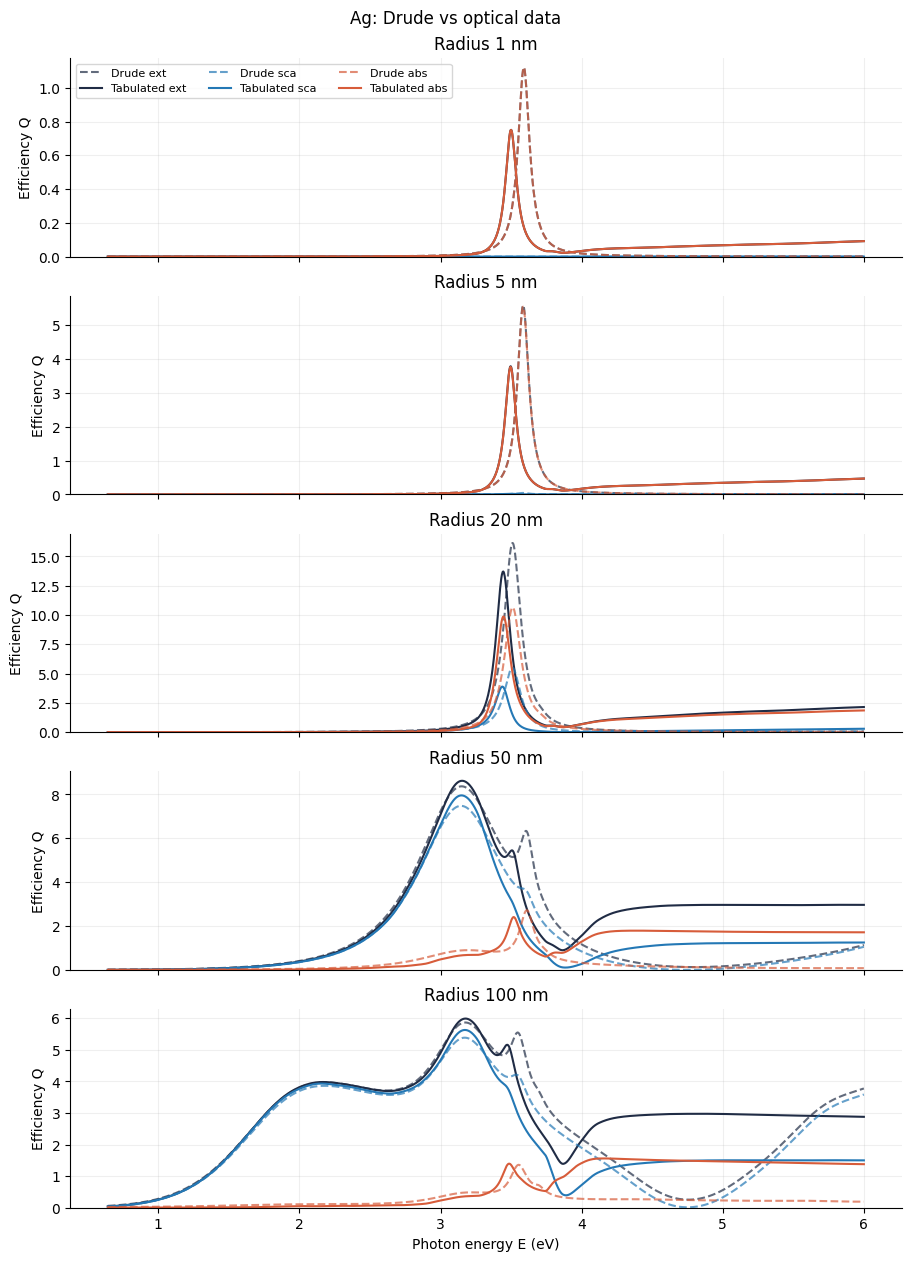

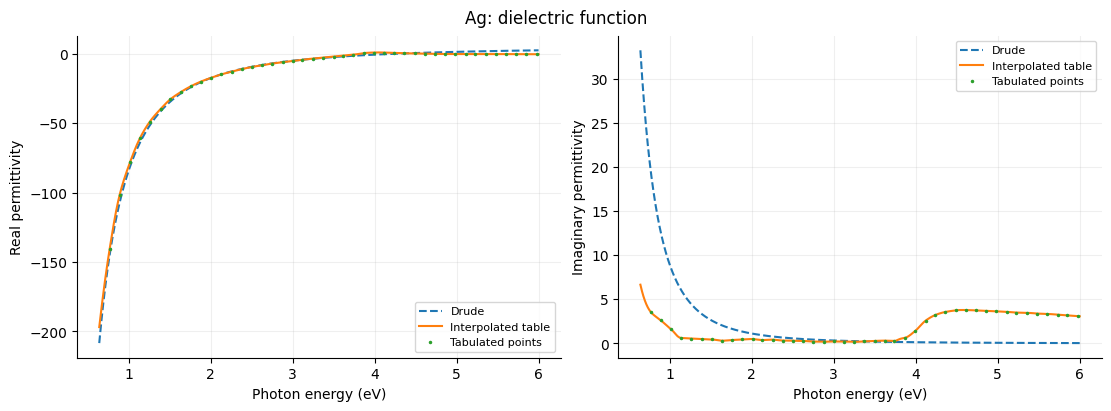

Ag, 100 nm: dominant extinction peak on shared window: Drude 3.1750 eV; tabulated 3.1775 eV. Reference N=15/15; stability errors 0.00e+00/0.00e+00.


In [19]:
if INCLUDE_EXPERIMENTAL:
    compare_with_data("Ag", ag_notes)
else:
    print("Experimental comparison skipped.")


### Optical data: aluminum

Repeat the comparison using the bundled Hagemann optical constants.


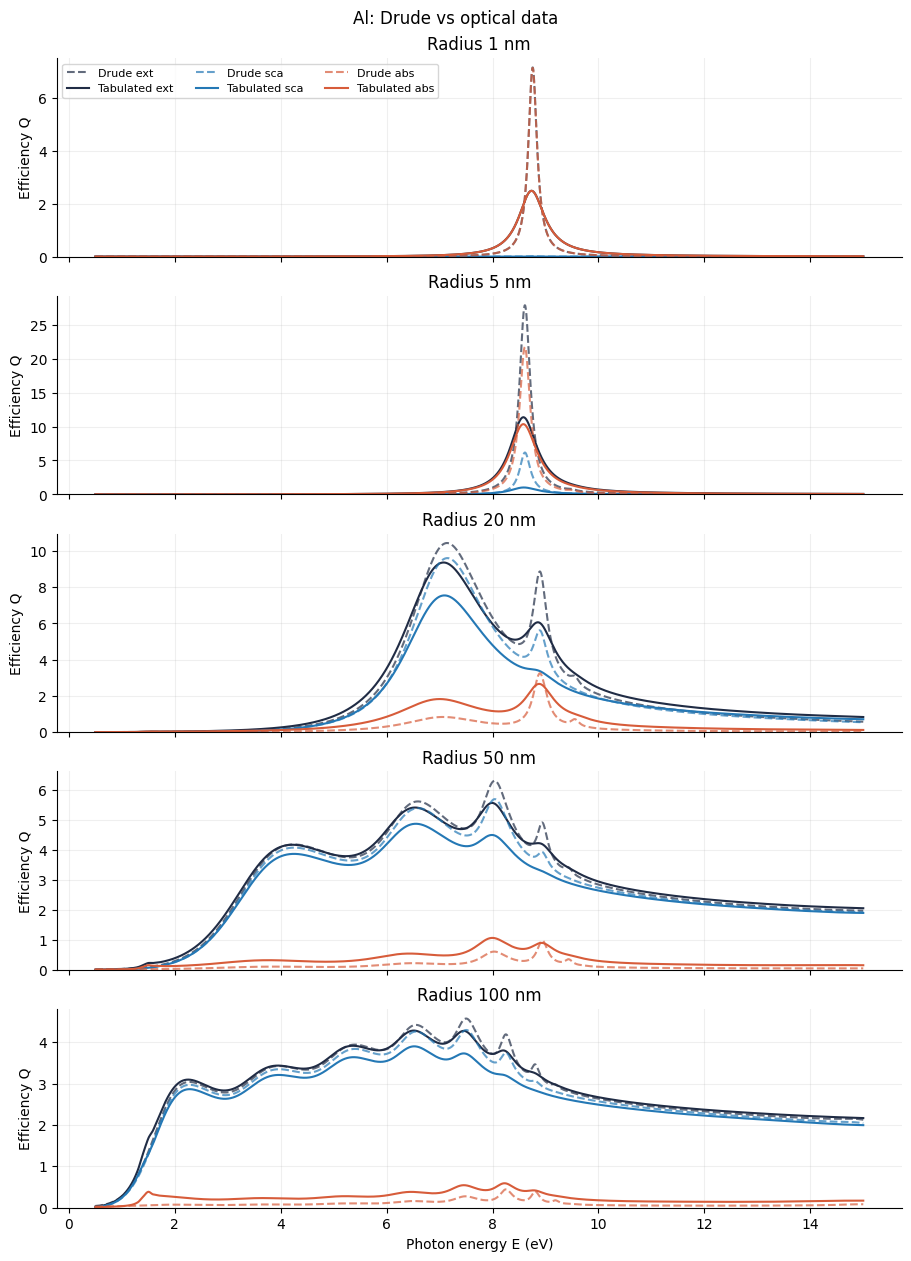

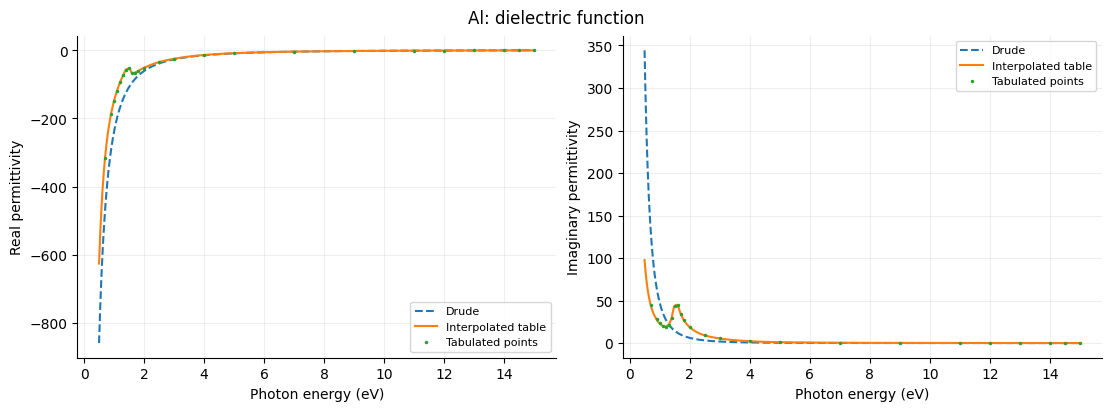

Al, 100 nm: dominant extinction peak on shared window: Drude 7.5000 eV; tabulated 6.5100 eV. Reference N=22/22; stability errors 0.00e+00/0.00e+00.


In [20]:
if INCLUDE_EXPERIMENTAL:
    compare_with_data("Al", al_notes)
else:
    print("Experimental comparison skipped.")


## 12. Electric field: silver

Show the total field, exterior scattered field, and a real-field snapshot near a 50 nm sphere.


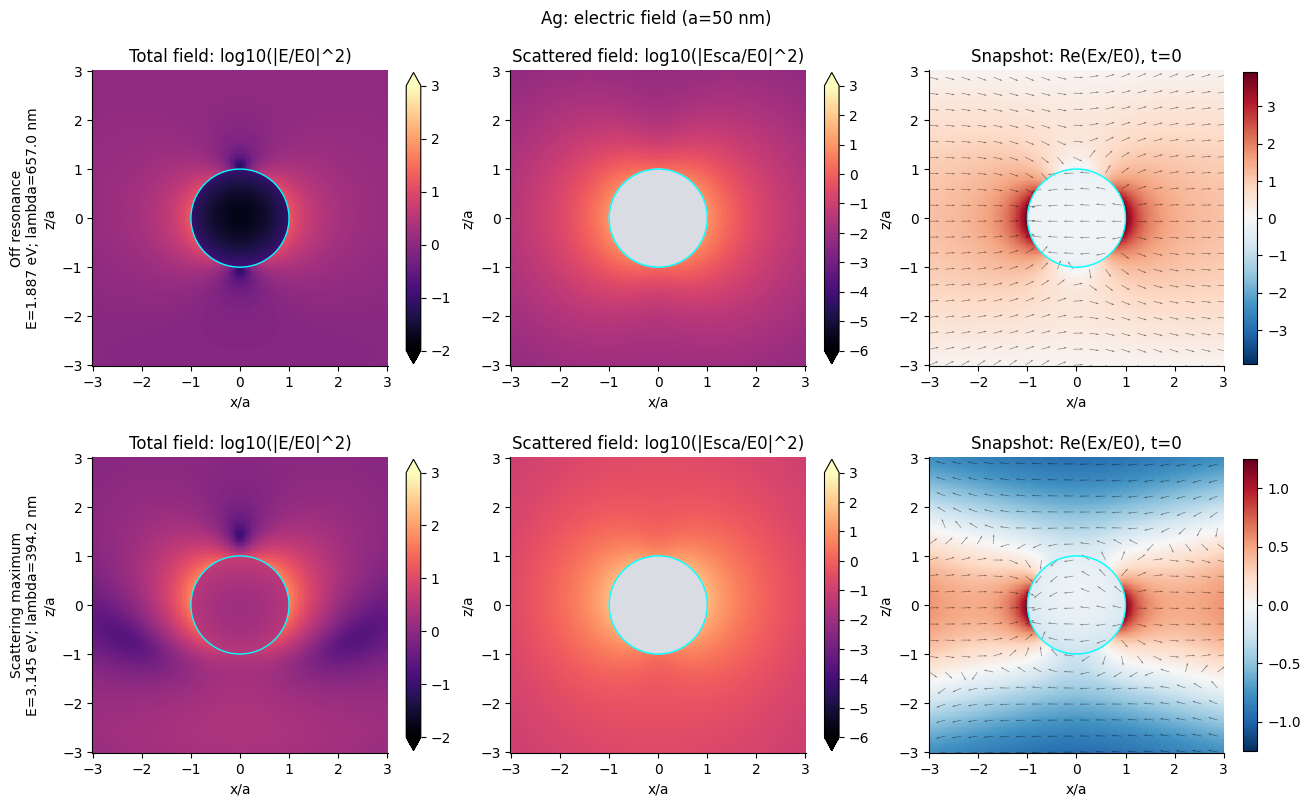

In [21]:
if MAKE_FIELD_MAPS:
    plot_fields("Ag", OUT, True, ag_notes)
    plt.show()
else:
    print("Field map skipped.")


### Electric field: aluminum

Show the same field maps for aluminum.


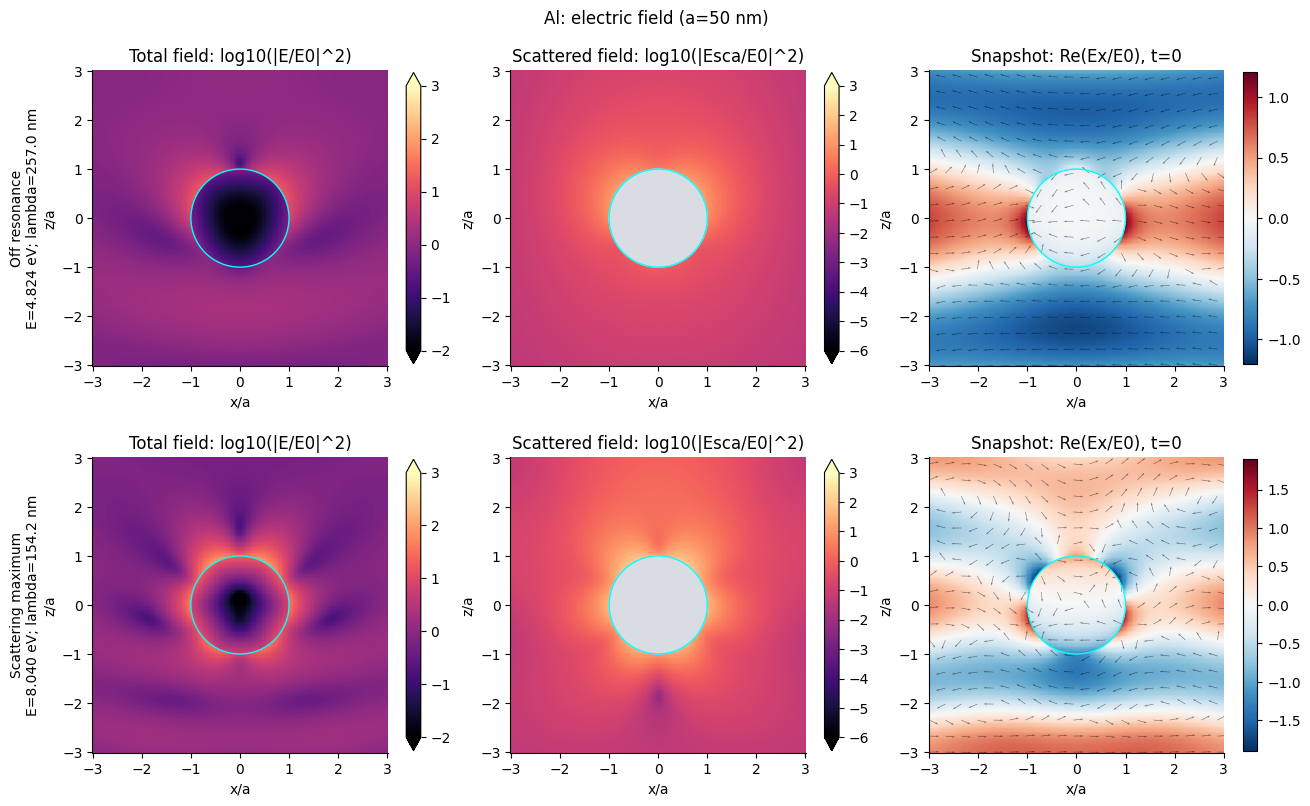

In [22]:
if MAKE_FIELD_MAPS:
    plot_fields("Al", OUT, True, al_notes)
    plt.show()
else:
    print("Field map skipped.")


## 13. Tables and concise summary

Save the convergence numbers, sampled spectral peaks, parameters and interpretation alongside the figures.


In [23]:
write_rows(OUT / "convergence.csv", ag_convergence + al_convergence)
write_rows(OUT / "spectral_peaks.csv", ag_peaks + al_peaks)
summary = ["NORDLANDER HOMEWORK 5: MIE SPECTRA", "", check_message, "",
    f"Host index={N_HOST}; relative permeability=1; homework N={N_HOMEWORK}.",
    "Convergence error: maximum spectral difference / peak of the reference spectrum.",
    "The 1% threshold is a chosen accuracy target. Peak positions are sampled maxima.", "",
    *ag_notes, "", *al_notes, "", "INTERPRETATION",
    "For small spheres, the electric dipole and absorption generally dominate.",
    "Larger spheres scatter more and higher multipoles can add spectral structure.",
    "Tabulated optical constants describe bulk material, not measured sphere spectra.",
    "At 1 nm the assigned local bulk model omits size-dependent and quantum effects.",
    "Al is modeled without a native oxide shell.", "", "DATA SOURCES",
    "Ag: data.d (Johnson and Christy, 1972), doi:10.1103/PhysRevB.6.4370.",
    "Al: Hagemann, Gudat and Kunz, doi:10.1364/JOSA.65.000742.",
    "See data/provenance.json for the table sources."]
(OUT / "results_summary.txt").write_text("\n".join(summary)+"\n", encoding="utf-8")
settings = {"radii_nm": RADII_NM, "n_host": N_HOST, "N_homework": N_HOMEWORK,
    "materials": MATERIALS, "field_radius_nm": FIELD_RADIUS_NM,
    "field_pixels": FIELD_PIXELS, "convergence_tolerance": CONVERGENCE_TOL,
    "reference_tolerance": REFERENCE_TOL}
(OUT / "settings.json").write_text(json.dumps(settings, indent=2)+"\n")
print(f"Files saved in {OUT}")


Files saved in C:\Users\perez\OneDrive\Documentos\RICE\ROTATIONS\Nordlander\HW5_Mie\HW5_Mie_single\results
